# Buổi 2 – Covariance, correlation, drawdown

GĐ 1, phần 2. Dùng lại batch raw của Buổi 1 (không tải lại dữ liệu).

1. Covariance và correlation của 7 mã (simple return ngày)
2. Volatility danh mục: tính bằng ma trận covariance phải khớp tính trực tiếp
3. Rolling correlation: tương quan tăng khi khủng hoảng
4. Drawdown: mức sụt từ đỉnh, thời gian hồi phục

Quy ước: return âm = lỗ; drawdown là số âm (−34% = đang thấp hơn đỉnh 34%).

In [1]:
import os, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RISKLAB_DATA = Path(os.environ["RISKLAB_DATA"])   # KeyError -> chưa `source session.sh`
RAW_DIR = RISKLAB_DATA / "raw" / "yfinance" / "prices_daily"

BENCHMARK = "SPY"
TRADING_DAYS = 252
ROLL_WINDOW = 63                                  # ~1 quý giao dịch

## 0. Nạp dữ liệu

Lấy batch mới nhất trong `raw` (tên batch là thời điểm UTC nên sắp xếp chữ = sắp xếp thời gian).
Return tính từ `adj_close` (đã gồm cổ tức và chia tách).

In [2]:
batches = sorted(p for p in RAW_DIR.glob("batch_id=*") if p.is_dir())
assert batches, f"Không thấy batch nào trong {RAW_DIR}"
BATCH = batches[-1]
print("Batch dùng:", BATCH.name)

raw = pd.read_parquet(BATCH / "prices.parquet")
print("Cột:", list(raw.columns))

# Bảng raw dạng dài: mỗi dòng = (ticker, trade_date). Xoay thành bảng rộng: cột = mã.
date_col = "trade_date" if "trade_date" in raw.columns else "date"
assert {"ticker", date_col, "adj_close"} <= set(raw.columns), (
    "Schema khác dự kiến – chép đoạn nạp dữ liệu của notebook 01 vào đây")
px = (raw.pivot(index=date_col, columns="ticker", values="adj_close")
         .sort_index())
px.index = pd.to_datetime(px.index)

STOCKS = [t for t in px.columns if t != BENCHMARK]
print("Danh mục:", STOCKS, "| benchmark:", BENCHMARK)
print(px.shape, px.index.min().date(), "->", px.index.max().date())

Batch dùng: batch_id=20261108T103206Z
Cột: ['ticker', 'trade_date', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'ingest_ts', 'source_system', 'batch_id']
Danh mục: ['AAPL', 'JPM', 'KO', 'MSFT', 'NVDA', 'PEP', 'TSLA'] | benchmark: SPY
(2980, 8) 2015-01-02 -> 2026-11-06


In [3]:
rets = px.pct_change().dropna(how="all")          # simple return ngày
assert rets.isna().sum().sum() == 0, "Có NaN – kiểm tra lịch giao dịch"
print(rets.shape)
rets.tail(3)

(2979, 8)


ticker,AAPL,JPM,KO,MSFT,NVDA,PEP,SPY,TSLA
trade_date,,,,,,,,
2026-11-04,0.053058,0.041807,0.010549,0.066815,-0.031738,0.037517,0.016518,-0.033400
2026-11-05,-0.015279,-0.041947,-0.000731,-0.035750,-0.092590,0.002036,-0.044092,-0.107739
2026-11-06,-0.005230,-0.008448,-0.000627,-0.009927,0.027753,-0.009600,0.003124,0.042276


## 1. Covariance và correlation

- **Covariance** đo hai mã có xu hướng lên xuống *cùng nhau* không, đơn vị là (return)² nên khó đọc.
- **Correlation** = covariance chia cho (vol A × vol B) → luôn nằm trong [−1, 1], dễ so sánh.
- Đường chéo của ma trận covariance chính là variance = vol² → phải khớp vol ở Buổi 1.

In [4]:
r = rets[STOCKS]
cov_d = r.cov()                       # covariance ngày (pandas dùng N-1)
cov_a = cov_d * TRADING_DAYS          # covariance năm: nhân 252 (variance cộng theo thời gian)
corr = r.corr()

vol_from_cov = np.sqrt(np.diag(cov_a))
vol_direct = r.std() * np.sqrt(TRADING_DAYS)
check = pd.DataFrame({"vol_tu_cov": vol_from_cov, "vol_truc_tiep": vol_direct}, index=STOCKS)
print("Đường chéo covariance khớp vol Buổi 1?", np.allclose(vol_from_cov, vol_direct))
display((check * 100).round(2))

display(corr.round(2))

Đường chéo covariance khớp vol Buổi 1? True


,vol_tu_cov,vol_truc_tiep
AAPL,28.66,28.66
JPM,26.85,26.85
KO,17.91,17.91
MSFT,27.61,27.61
NVDA,48.06,48.06
PEP,19.30,19.30
TSLA,57.02,57.02


ticker,AAPL,JPM,KO,MSFT,NVDA,PEP,TSLA
ticker,,,,,,,
AAPL,1.00,0.41,0.33,0.62,0.50,0.38,0.41
JPM,0.41,1.00,0.39,0.42,0.33,0.33,0.28
KO,0.33,0.39,1.00,0.31,0.13,0.71,0.11
MSFT,0.62,0.42,0.31,1.00,0.57,0.35,0.39
NVDA,0.50,0.33,0.13,0.57,1.00,0.16,0.42
PEP,0.38,0.33,0.71,0.35,0.16,1.00,0.13
TSLA,0.41,0.28,0.11,0.39,0.42,0.13,1.00


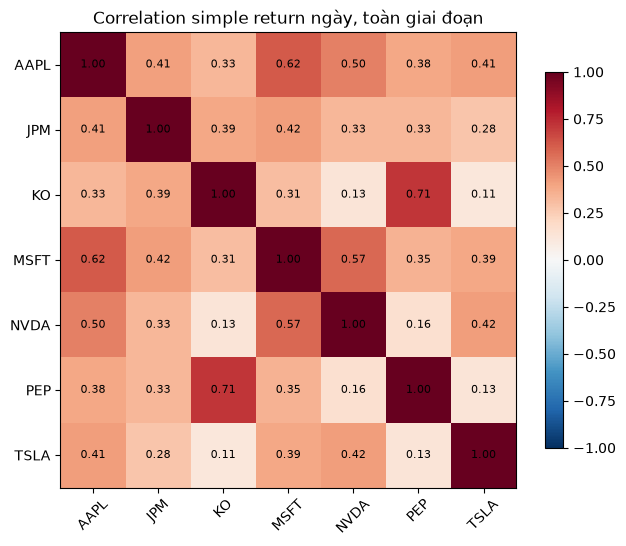

Thấp nhất:
 ticker  ticker
KO      TSLA      0.11
        NVDA      0.13
PEP     TSLA      0.13
dtype: float64
Cao nhất:
 ticker  ticker
MSFT    NVDA      0.57
AAPL    MSFT      0.62
KO      PEP       0.71
dtype: float64


In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(STOCKS)), STOCKS, rotation=45)
ax.set_yticks(range(len(STOCKS)), STOCKS)
for i in range(len(STOCKS)):
    for j in range(len(STOCKS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation simple return ngày, toàn giai đoạn")
plt.tight_layout(); plt.show()

# Cặp tương quan cao nhất / thấp nhất (chỉ lấy tam giác trên, bỏ đường chéo)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().dropna().sort_values()   # pandas 3: stack không tự bỏ NaN
print("Thấp nhất:\n", pairs.head(3).round(2))
print("Cao nhất:\n", pairs.tail(3).round(2))

### Ma trận có "xác định dương" không?

GĐ 4 sẽ phân rã Cholesky ma trận này để sinh số ngẫu nhiên có tương quan. Cholesky chỉ chạy khi mọi
eigenvalue > 0. Hôm nay chỉ kiểm tra, chưa cần hiểu sâu.

In [6]:
eig = np.linalg.eigvalsh(cov_a)
print("Eigenvalue (nhỏ -> lớn):", np.round(eig, 5))
print("Xác định dương:", bool((eig > 0).all()))
print(f"Thành phần lớn nhất giải thích {eig[-1] / eig.sum():.0%} tổng variance "
      "(≈ 'yếu tố thị trường' kéo mọi mã cùng chiều)")

Eigenvalue (nhỏ -> lớn): [0.00957 0.02958 0.03584 0.04608 0.09263 0.16923 0.47295]
Xác định dương: True
Thành phần lớn nhất giải thích 55% tổng variance (≈ 'yếu tố thị trường' kéo mọi mã cùng chiều)


## 2. Volatility danh mục trọng số bằng nhau

Hai cách phải ra cùng một số:

- **Trực tiếp**: tạo chuỗi return danh mục `r_p = Σ w_i r_i` mỗi ngày rồi lấy độ lệch chuẩn.
- **Qua ma trận**: `σ_p² = wᵀ Σ w`. Đây là cách Parametric VaR (GĐ 3) dùng, vì đổi trọng số
  không cần tính lại chuỗi return.

Giả định: tái cân bằng về trọng số bằng nhau **mỗi ngày** (đơn giản; buy-and-hold sẽ trôi trọng số).

In [7]:
w = np.full(len(STOCKS), 1 / len(STOCKS))
port = r @ w                                        # Series return danh mục ngày

vol_p_direct = port.std() * np.sqrt(TRADING_DAYS)
vol_p_matrix = np.sqrt(w @ cov_a.values @ w)
vol_weighted_avg = w @ vol_direct.values            # nếu mọi correlation = 1

print(f"Vol danh mục (trực tiếp)      : {vol_p_direct:.2%}")
print(f"Vol danh mục (wᵀΣw)            : {vol_p_matrix:.2%}")
print(f"Trung bình có trọng số các vol : {vol_weighted_avg:.2%}  <- nếu correlation = 1")
print(f"Diversification ratio          : {vol_weighted_avg / vol_p_matrix:.2f}")
print(f"SPY                            : {vol_direct.get(BENCHMARK, rets[BENCHMARK].std()*np.sqrt(TRADING_DAYS)):.2%}")
assert np.isclose(vol_p_direct, vol_p_matrix), "Hai cách phải khớp"

Vol danh mục (trực tiếp)      : 22.10%
Vol danh mục (wᵀΣw)            : 22.10%
Trung bình có trọng số các vol : 32.20%  <- nếu correlation = 1
Diversification ratio          : 1.46
SPY                            : 17.54%


In [8]:
# Đóng góp rủi ro theo mã (sẽ dùng lại ở GĐ 6): RC_i = w_i * (Σw)_i / σ_p ; tổng = σ_p
marginal = cov_a.values @ w / vol_p_matrix
rc = pd.Series(w * marginal, index=STOCKS)
rc_pct = (rc / rc.sum()).sort_values(ascending=False)
print("Tổng RC = vol danh mục?", np.isclose(rc.sum(), vol_p_matrix))
display(pd.DataFrame({"trong_so": 1 / len(STOCKS), "dong_gop_rui_ro": rc_pct}).style.format("{:.1%}"))

Tổng RC = vol danh mục? True


,trong_so,dong_gop_rui_ro
TSLA,14.3%,26.6%
NVDA,14.3%,23.3%
AAPL,14.3%,14.1%
MSFT,14.3%,13.7%
JPM,14.3%,10.7%
PEP,14.3%,6.2%
KO,14.3%,5.4%


## 3. Rolling correlation – tương quan có ổn định không?

Correlation toàn giai đoạn là *một con số trung bình*. Tính lại trên cửa sổ 63 phiên trượt dần để xem
nó thay đổi thế nào, đặc biệt 3/2020 và 2022.

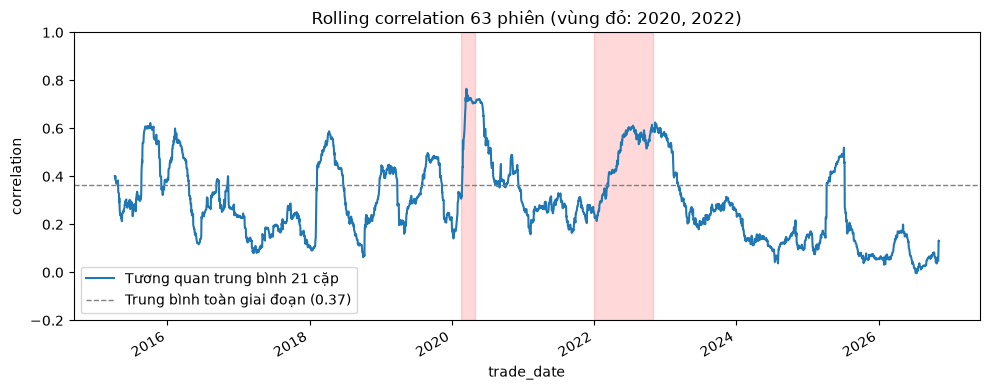

Thấp nhất: -0.00 (2026-07-14)
Cao nhất : 0.76 (2020-03-16)


In [9]:
roll_corr = r.rolling(ROLL_WINDOW).corr()          # MultiIndex (ngày, mã) x mã
n = len(STOCKS)
iu = np.triu_indices(n, k=1)

def avg_pairwise(block):
    m = block.values
    vals = m[iu] if m.shape == (n, n) else np.array([np.nan])
    return vals.mean() if np.isfinite(vals).all() else np.nan   # 62 phiên đầu chưa đủ cửa sổ

avg_corr = roll_corr.groupby(level=0).apply(avg_pairwise).dropna()
corr_vs_spy = r.rolling(ROLL_WINDOW).corr(rets[BENCHMARK]).dropna(how="all")

fig, ax = plt.subplots(figsize=(10, 4))
avg_corr.plot(ax=ax, label="Tương quan trung bình 21 cặp")
ax.axhline(pairs.mean(), ls="--", c="grey", lw=1, label=f"Trung bình toàn giai đoạn ({pairs.mean():.2f})")
for start, end in [("2020-02-15", "2020-04-30"), ("2022-01-01", "2022-10-31")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.15, color="red")
ax.set_ylim(-0.2, 1); ax.set_ylabel("correlation"); ax.legend(loc="lower left")
ax.set_title(f"Rolling correlation {ROLL_WINDOW} phiên (vùng đỏ: 2020, 2022)")
plt.tight_layout(); plt.show()

print(f"Thấp nhất: {avg_corr.min():.2f} ({avg_corr.idxmin().date()})")
print(f"Cao nhất : {avg_corr.max():.2f} ({avg_corr.idxmax().date()})")

In [10]:
# So sánh correlation trung bình theo giai đoạn
periods = {
    "Bình thường 2017": ("2017-01-01", "2017-12-31"),
    "COVID 2020-02-20 → 2020-04-30": ("2020-02-20", "2020-04-30"),
    "2022": ("2022-01-01", "2022-12-31"),
    "Toàn giai đoạn": (str(r.index.min().date()), str(r.index.max().date())),
}
rows = []
for name, (a, b) in periods.items():
    sub = r.loc[a:b]
    c = sub.corr().values[iu].mean()
    rows.append({"giai_doan": name, "so_phien": len(sub), "corr_tb": round(c, 2),
                 "vol_danh_muc_nam": f"{(sub @ w).std() * np.sqrt(TRADING_DAYS):.1%}"})
pd.DataFrame(rows)

,giai_doan,so_phien,corr_tb,vol_danh_muc_nam
0,Bình thường 2017,251,0.15,11.8%
1,COVID 2020-02-20 → 2020-04-30,50,0.73,76.6%
2,2022,251,0.53,30.7%
3,Toàn giai đoạn,2979,0.37,22.1%


## 4. Drawdown

Nếu đã đầu tư 1 đồng từ đầu:

1. **Wealth index** `W_t = Π(1 + r)` – giá trị tài khoản theo thời gian.
2. **Đỉnh đến nay** `M_t = max(W_0 … W_t)`.
3. **Drawdown** `DD_t = W_t / M_t − 1` – đang thấp hơn đỉnh bao nhiêu %. Bằng 0 khi đang ở đỉnh mới.
4. **Max drawdown** = DD nhỏ nhất (âm nhất). Kèm ngày đỉnh, ngày đáy, ngày hồi phục về đỉnh cũ.

Drawdown đo **đường đi**, volatility không thấy: hai chuỗi cùng vol có thể có max drawdown rất khác.

In [11]:
def drawdown_stats(ret: pd.Series) -> dict:
    wealth = (1 + ret).cumprod()
    peak = wealth.cummax()
    dd = wealth / peak - 1
    trough = dd.idxmin()
    peak_date = wealth.loc[:trough].idxmax()
    after = wealth.loc[trough:]
    recovered = after[after >= wealth.loc[peak_date]]
    rec_date = recovered.index[0] if len(recovered) else pd.NaT
    return {
        "max_drawdown": dd.min(),
        "ngay_dinh": peak_date.date(),
        "ngay_day": trough.date(),
        "ngay_hoi_phuc": rec_date.date() if pd.notna(rec_date) else "chưa hồi phục",
        "phien_dinh_den_day": len(wealth.loc[peak_date:trough]) - 1,
        "phien_day_den_hoi_phuc": (len(wealth.loc[trough:rec_date]) - 1) if pd.notna(rec_date) else None,
    }

series = {**{t: rets[t] for t in STOCKS}, BENCHMARK: rets[BENCHMARK], "PORT_EW": port}
dd_table = pd.DataFrame({k: drawdown_stats(v) for k, v in series.items()}).T
dd_table["vol_nam"] = [s.std() * np.sqrt(TRADING_DAYS) for s in series.values()]
dd_table = dd_table.sort_values("max_drawdown")
display(dd_table.style.format({"max_drawdown": "{:.1%}", "vol_nam": "{:.1%}"}))

,max_drawdown,ngay_dinh,ngay_day,ngay_hoi_phuc,phien_dinh_den_day,phien_day_den_hoi_phuc,vol_nam
TSLA,-73.6%,2021-11-04,2023-01-03,2024-12-11,291,488,57.0%
NVDA,-66.3%,2021-11-29,2022-10-14,2023-05-25,221,153,48.1%
JPM,-43.6%,2020-01-02,2020-03-23,2021-01-07,55,201,26.8%
AAPL,-38.5%,2018-10-03,2019-01-03,2019-10-10,62,194,28.7%
MSFT,-37.1%,2021-11-19,2022-11-03,2023-06-15,240,153,27.6%
KO,-37.0%,2020-02-21,2020-03-23,2021-07-27,21,339,17.9%
PORT_EW,-35.5%,2020-02-19,2020-03-23,2020-06-10,23,55,22.1%
SPY,-33.7%,2020-02-19,2020-03-23,2020-08-10,23,97,17.5%
PEP,-30.3%,2023-05-12,2025-05-14,chưa hồi phục,502,None,19.3%


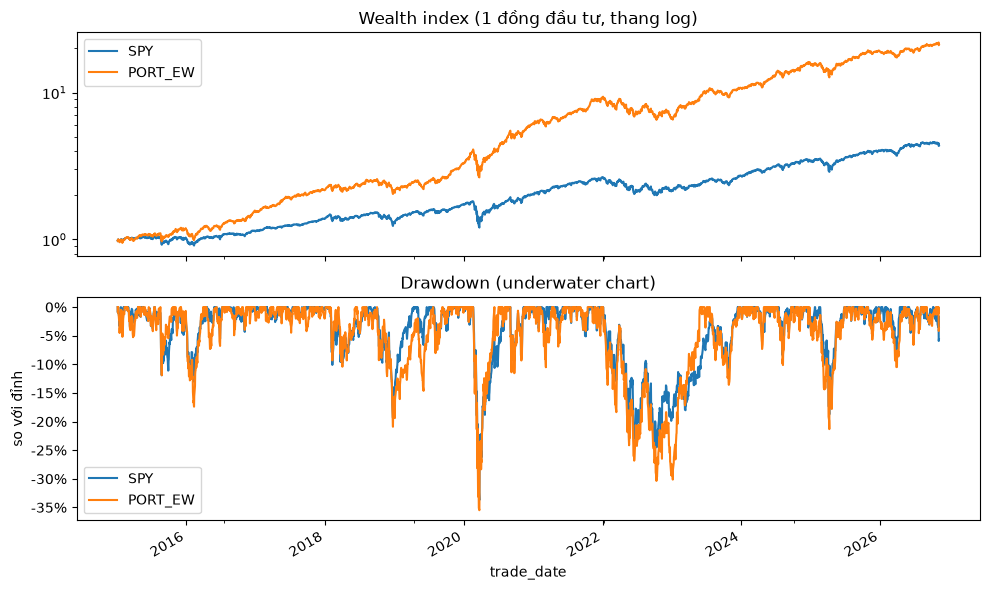

In [12]:
def dd_series(ret):
    w_ = (1 + ret).cumprod()
    return w_ / w_.cummax() - 1

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for name in [BENCHMARK, "PORT_EW"]:
    (1 + series[name]).cumprod().plot(ax=axes[0], label=name, logy=True)
    dd_series(series[name]).plot(ax=axes[1], label=name)
axes[0].set_title("Wealth index (1 đồng đầu tư, thang log)"); axes[0].legend()
axes[1].set_title("Drawdown (underwater chart)"); axes[1].set_ylabel("so với đỉnh")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].legend()
plt.tight_layout(); plt.show()

In [13]:
# Drawdown lớn nhất trong từng giai đoạn khủng hoảng (tính lại đỉnh trong giai đoạn)
crises = {"2020": ("2020-01-01", "2020-12-31"), "2022": ("2022-01-01", "2022-12-31")}
out = {}
for name, (a, b) in crises.items():
    out[name] = {k: dd_series(v.loc[a:b]).min() for k, v in series.items()}
pd.DataFrame(out).sort_values("2020").style.format("{:.1%}")

,2020,2022
TSLA,-60.6%,-72.7%
JPM,-43.6%,-37.9%
NVDA,-37.6%,-62.7%
KO,-37.0%,-16.7%
PORT_EW,-35.5%,-30.4%
SPY,-33.7%,-24.5%
AAPL,-31.4%,-30.3%
PEP,-28.8%,-11.9%
MSFT,-28.0%,-35.6%


## 5. Tóm tắt để ghi vào "Ghi chú của tôi"

Chạy ô dưới, dán output vào chat.

In [14]:
summary = {
    "batch": BATCH.name,
    "so_phien_return": len(rets),
    "corr_thap_nhat": f"{pairs.index[0][0]}-{pairs.index[0][1]} {pairs.iloc[0]:.2f}",
    "corr_cao_nhat": f"{pairs.index[-1][0]}-{pairs.index[-1][1]} {pairs.iloc[-1]:.2f}",
    "corr_tb_toan_giai_doan": round(pairs.mean(), 2),
    "rolling_corr_min_max": f"{avg_corr.min():.2f} ({avg_corr.idxmin().date()}) / {avg_corr.max():.2f} ({avg_corr.idxmax().date()})",
    "vol_port_ew": f"{vol_p_matrix:.2%}",
    "vol_tb_trong_so": f"{vol_weighted_avg:.2%}",
    "diversification_ratio": round(vol_weighted_avg / vol_p_matrix, 2),
    "rc_lon_nhat": f"{rc_pct.index[0]} {rc_pct.iloc[0]:.1%}",
    "mdd_spy": f"{dd_table.loc[BENCHMARK, 'max_drawdown']:.1%} ({dd_table.loc[BENCHMARK, 'ngay_dinh']} -> {dd_table.loc[BENCHMARK, 'ngay_day']}, hồi phục: {dd_table.loc[BENCHMARK, 'ngay_hoi_phuc']})",
    "mdd_port_ew": f"{dd_table.loc['PORT_EW', 'max_drawdown']:.1%} ({dd_table.loc['PORT_EW', 'ngay_dinh']} -> {dd_table.loc['PORT_EW', 'ngay_day']})",
    "mdd_te_nhat": f"{dd_table.index[0]} {dd_table['max_drawdown'].iloc[0]:.1%}",
    "eigen_min": float(eig[0]),
}
print(json.dumps(summary, ensure_ascii=False, indent=2, default=str))

{
  "batch": "batch_id=20261108T103206Z",
  "so_phien_return": 2979,
  "corr_thap_nhat": "KO-TSLA 0.11",
  "corr_cao_nhat": "KO-PEP 0.71",
  "corr_tb_toan_giai_doan": 0.37,
  "rolling_corr_min_max": "-0.00 (2026-07-14) / 0.76 (2020-03-16)",
  "vol_port_ew": "22.10%",
  "vol_tb_trong_so": "32.20%",
  "diversification_ratio": 1.46,
  "rc_lon_nhat": "TSLA 26.6%",
  "mdd_spy": "-33.7% (2020-02-19 -> 2020-03-23, hồi phục: 2020-08-10)",
  "mdd_port_ew": "-35.5% (2020-02-19 -> 2020-03-23)",
  "mdd_te_nhat": "TSLA -73.6%",
  "eigen_min": 0.009572283160409869
}
